In [1]:
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt
%matplotlib inline

import matplotlib
matplotlib.rcParams['lines.linewidth'] = 1

from scipy.integrate import simpson as simps

from scipy import interpolate
import scipy.constants as _con
c = _con.c  # Speed of light (m/s)

In [2]:
# filter_folder = "./BLAST/"

# window = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - Window.tsv', usecols = (3,2)).T
# IR300  = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - 300K IR C7.5.tsv', usecols = (3,2)).T
# IRVCS  = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - VCS1 and VCS2 IR - DS7.5.tsv', usecols = (3,2)).T
# LPEVCS = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - VCS1 LPE - 80cm^-1.tsv', usecols = (3,2)).T
# IR4K   = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - 4K IR - C15.tsv', usecols = (3,2)).T
# LPE4K  = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - 4K LPE - 65 cm^-1.tsv', usecols = (3,2)).T
# OBLPE4K = np.loadtxt(filter_folder+ 'BLAST_transmissivity.xlsx - 4K OB LPE - 60cm^-1.tsv', usecols = (3,2)).T

In [3]:
# filter_folder = "./Cardiff_caltech/"

# F100icm  = np.loadtxt(filter_folder+'202308_FP3310_100icm_PreARCoat.tsv', usecols = (0,1)).T
# F57icm  = np.loadtxt(filter_folder+'202308_FP3313_57icm_PreARCoat_T1929R7.tsv', usecols = (0,1)).T

# F42icm = np.loadtxt(filter_folder+'202308_FP3193_42icm_PreARCoat.tsv', usecols = (0,1)).T

In [4]:
filter_folder = "/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Cardiff_TIM_202505/"


P34507 = np.loadtxt(filter_folder+'202505_P34507_P34508_C7.5.tsv', usecols = (0,2), skiprows=1).T
P34508 = np.loadtxt(filter_folder+'202505_P34507_P34508_C7.5.tsv', usecols = (0,1), skiprows=1).T

FP3373ARC  = np.loadtxt(filter_folder+"202505_FP3373ARC_VCS2_T1934R13.tsv", usecols = (0,1), skiprows=1).T
FP3464ARC  = np.loadtxt(filter_folder+"202505_FP3464ARC_VCS1_T1947R19.tsv", usecols = (0,1), skiprows=1).T

FP3311ARC  = np.loadtxt(filter_folder+"202505_FP3311ARC_100icm_T1947R22.tsv", usecols = (0,1), skiprows=1).T
FP3480ARC  = np.loadtxt(filter_folder+"202505_FP3480ARC_65icm_T1947R13.tsv", usecols = (0,1), skiprows=1).T

FP3313  = np.loadtxt(filter_folder+"202505_FP3313_57icm_T1929R7.tsv", usecols = (0,1), skiprows=1).T
FP3314  = np.loadtxt(filter_folder+"202505_FP3314_42icm_T1929R3.tsv", usecols = (0,1), skiprows=1).T

FP3315  = np.loadtxt(filter_folder+"202505_FP3315_33icm_T1929R9.tsv", usecols = (0,1), skiprows=1).T
FP3316  = np.loadtxt(filter_folder+"202505_FP3316_42icm_T1929R5.tsv", usecols = (0,1), skiprows=1).T



In [5]:
def icm2um(x):
    # Convert inverse centimeters (icm) to microns (μm)
    # 1 icm = 1/(100*x) meters = 10000/x microns
    return 10000 / x

# Convert wavelength to wavenumber
def um2icm(x):
    return 10000 / x

def icm2GHz(x):
    # Convert inverse centimeters (icm) to GHz
    # 1 icm = 1 cm^-1 = 29.9792458 GHz
    return 100*x *c *1e-9

print(icm2GHz(1), icm2um(100))

29.9792458 100.0


In [6]:
def planck(wavelength, temperature):
    """Calculate Planck's law for blackbody radiance at given wavelength and temperature"""
    h = _con.h # Planck's constant
    k = _con.k  # Boltzmann constant
    a = 2.0 * h * c**2
    b = (h * c) / (wavelength * 1e-6 * k * temperature)
    intensity = a / ((wavelength * 1e-6)**5 * (np.exp(b) - 1.0))
    return intensity

def plot_blackbody(ax, temperatures=[2.7, 300], wavelength_range=(10, 1000), relative=True):
    """
    Plot blackbody spectra with filter transmission curves

    Parameters:
    ax: matplotlib axes object to plot on
    temperatures: list of temperatures to plot (K)
    wavelength_range: tuple of (min, max) wavelengths to plot (um)
    """

    # Plot blackbody curves
    wavelengths = np.linspace(*wavelength_range, 10001)
    for T in temperatures:
        spectrum = planck(wavelengths, T)
        if relative:
            spectrum = spectrum/np.max(spectrum)
        ax.plot(wavelengths, spectrum*1e-6,  # turn to W/m^2/sr/um instead of W/m^3/sr
                label=f'Blackbody {T}K', alpha=0.7, lw=0.75, ls='--')

    if relative:
        ax.set_xlabel('Wavelength [μm]')
        ax.set_ylabel('Normalized Intensity')
        ax.set_yscale('linear')
    else:
        ax.set_xlabel('Wavelength [μm]')
        ax.set_ylabel('Intensity [W/m$^2$/sr/μm]')
        ax.set_yscale('log')
        ax.set_ylim(1e-15, 1e2)

    ax.set_xscale('log')
    ax.set_xlim(wavelength_range)





In [7]:
print(icm2GHz(P34508[0]))

[   299.792458     314.7820809    329.7717038 ... 149851.2601313
 149866.2497542 149881.2393771]


In [8]:
print(icm2GHz(FP3373ARC[0]))


[ 603.27440182  607.0214478   610.76849377  614.51553974  618.26258572
  622.00963169  625.75667767  629.50372364  633.25076961  636.99781559
  640.74486156  644.49190754  648.23895351  651.98599948  655.73304546
  659.48009143  663.22713741  666.97418338  670.72122936  674.46827533
  678.2153213   681.96236728  685.70941325  689.45645923  693.2035052
  696.95055117  700.69759715  704.44464312  708.1916891   711.93873507
  715.68578104  719.43282702  723.17987299  726.92691897  730.67396494
  734.42101091  738.16805689  741.91510286  745.66214884  749.40919481
  753.15624078  756.90328676  760.65033273  764.39737871  768.14442468
  771.89147065  775.63851663  779.3855626   783.13260858  786.87965455
  790.62670052  794.3737465   798.12079247  801.86783845  805.61488442
  809.36193039  813.10897637  816.85602234  820.60306832  824.35011429
  828.09716027  831.84420624  835.59125221  839.33829819  843.08534416
  846.83239014  850.57943611  854.32648208  858.07352806  861.82057403
  865.5

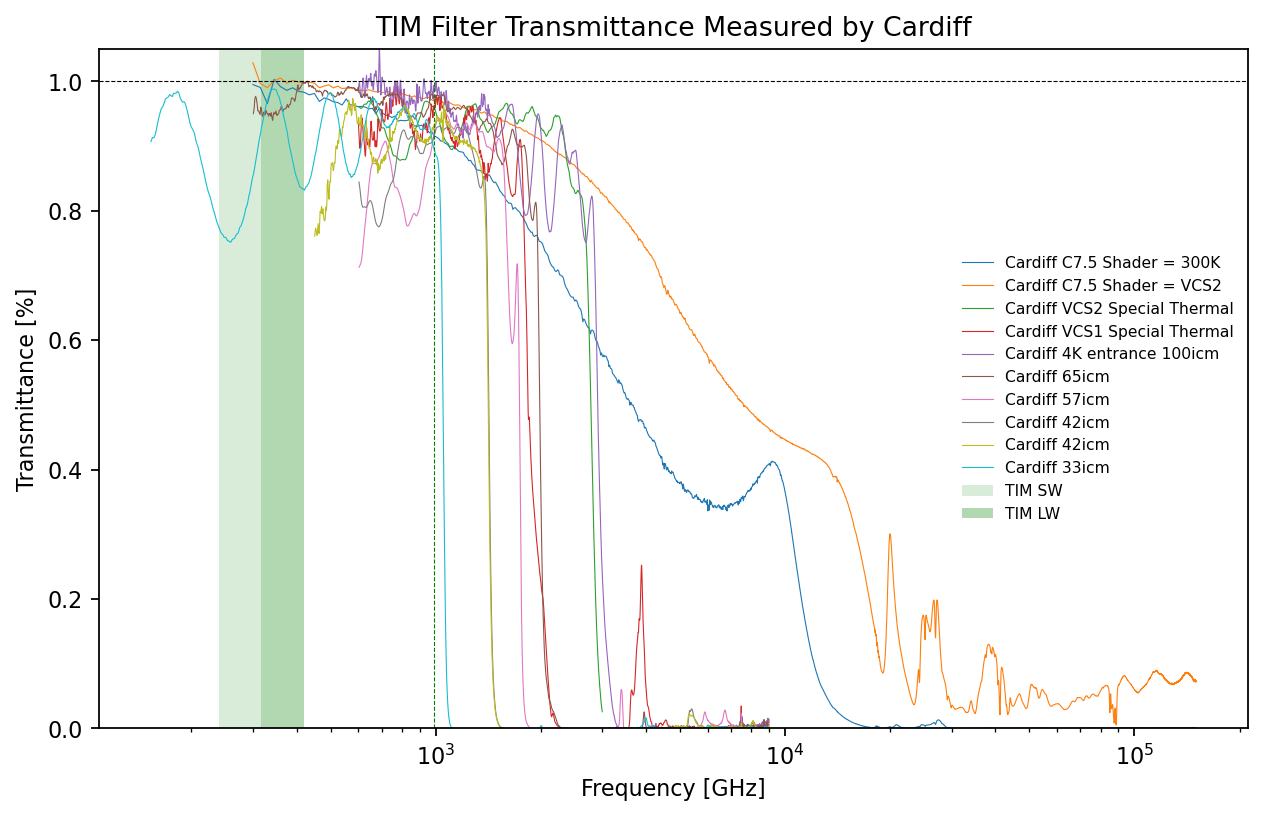

In [9]:
icm2GHzfig,ax=plt.subplots(1,1, figsize=(8,5), dpi=160)

# plt.plot(window[0],window[1], label='window')
# plt.plot(IR300[0],IR300[1], label='300K IR')
# plt.plot(IRVCS[0],IRVCS[1], label='VCS IR')
# plt.plot(LPEVCS[0],LPEVCS[1], label='VCS LPE')
# plt.plot(IR4K[0],IR4K[1], label='4K IR')
# plt.plot(LPE4K[0],LPE4K[1], label='4K LPE')
# plt.plot(OBLPE4K[0],OBLPE4K[1], label='4K OB LPE')

# plt.plot(icm2um(F100icm[0]), F100icm[1], label='Cardiff 100icm')
# plt.plot(icm2um(F57icm[0]), F57icm[1], label='Cardiff 57icm')
# plt.plot(icm2um(F42icm[0]), F42icm[1], label='Cardiff 42icm')

plt.plot(icm2GHz(P34507[0]), P34507[1], label='Cardiff C7.5 Shader = 300K', lw=0.5)

plt.plot(icm2GHz(P34508[0]), P34508[1], label='Cardiff C7.5 Shader = VCS2', lw=0.5)
plt.plot(icm2GHz(FP3373ARC[0]), FP3373ARC[1], label='Cardiff VCS2 Special Thermal', lw=0.5)

plt.plot(icm2GHz(FP3464ARC[0]), FP3464ARC[1], label='Cardiff VCS1 Special Thermal', lw=0.5)

plt.plot(icm2GHz(FP3311ARC[0]), FP3311ARC[1], label='Cardiff 4K entrance 100icm', lw=0.5)
plt.plot(icm2GHz(FP3480ARC[0]), FP3480ARC[1], label='Cardiff 65icm', lw=0.5) #Grating filter, not being used for TIM

plt.plot(icm2GHz(FP3313[0]), FP3313[1], label='Cardiff 57icm', lw=0.5)
plt.plot(icm2GHz(FP3314[0]), FP3314[1], label='Cardiff 42icm', lw=0.5)

plt.plot(icm2GHz(FP3316[0]), FP3316[1], label='Cardiff 42icm', lw=0.5)
plt.plot(icm2GHz(FP3315[0]), FP3315[1], label='Cardiff 33icm', lw=0.5)

plt.axvspan(240,317, color='g', alpha=0.15, label='TIM SW', lw=0)
plt.axvspan(317,420, color='g', alpha=0.3, label='TIM LW', lw=0)
plt.axhline(1, ls='--', c='k', lw=0.5)

# plt.xlim([600,1200])
plt.ylim([0,1.05])
plt.xscale('log')

# plt.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
# ax[0].get_xaxis().set_minor_formatter(matplotlib.ticker.ScalarFormatter())
# [plt].set_xticks([10, 20, 50, 100, 200, 500, 1000, 2000])
# ax[0].set_xlabel('Wavelength [um]')
plt.ylabel('Transmittance [%]')

plt.legend(frameon=0,fontsize=7, loc='center right')
plt.xlabel('Frequency [GHz]')


# plot_blackbody(ax[1], temperatures=[300, 160, 60, 10, 4], wavelength_range=(3, 2000), relative=False)

# ax[1].legend(frameon=0,fontsize=8)

# # Add secondary x-axis for wavenumber (icm)
# ax2 = ax[0].twiny()

# # Set wavenumber limits based on wavelength limits
# wl_min, wl_max = ax[0].get_xlim()
# icm_max = um2icm(wl_min)
# icm_min = um2icm(wl_max)
# ax2.set_xlim(icm_max, icm_min)
# ax2.set_xscale('log')
# ax2.set_xlabel('Wavenumber [cm$^{-1}$]')

# current_ticks = ax2.get_xticks()
# ax2.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())

# # Add third x-axis for frequency (THz)
# ax3 = ax[0].twiny()

# # Convert wavelength to frequency in THz (c = 299.792458 um/ps, so f_THz = c/lambda_um)
# freq_max = c*1e-6 / wl_min  # THz
# freq_min = c*1e-6 / wl_max  # THz
# ax3.set_xlim(freq_max, freq_min)
# ax3.set_xscale('log')
# ax3.set_xlabel('Frequency [THz]')

# ax3.get_xaxis().set_major_formatter(matplotlib.ticker.FormatStrFormatter('%d'))

# # Offset the third axis to avoid overlap with the second axis
# ax3.spines['top'].set_position(('outward', 40))

plt.axvline(990, ls='--', c='g', lw=0.5)
plt.tight_layout()
plt.title("TIM Filter Transmittance Measured by Cardiff")
plt.savefig('TIM_filters_Transmission_plot.pdf', dpi=200)

In [10]:
def freq_mask(data):
    freq = icm2GHz(data[0])
    mask = (freq >= 600) & (freq <= 1200)
    return freq[mask], data[1][mask]

P34508_freq, P34508_T = freq_mask(P34508)
FP3373ARC_freq, FP3373ARC_T = freq_mask(FP3373ARC)

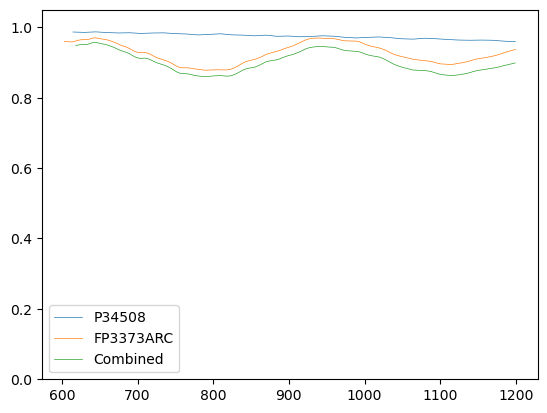

In [11]:
from scipy.interpolate import interp1d

# Interpolate P34508 onto FP3373ARC's frequency grid
P34508_interp = interp1d(P34508_freq, P34508_T, bounds_error=False, fill_value=np.nan)
P34508_T_resampled = P34508_interp(FP3373ARC_freq)

# Now multiply
combined_T = FP3373ARC_T * P34508_T_resampled

plt.plot(P34508_freq, P34508_T, label='P34508', lw=0.5)
plt.plot(FP3373ARC_freq, FP3373ARC_T, label='FP3373ARC', lw=0.5)
plt.plot(FP3373ARC_freq, combined_T, label='Combined', lw=0.5)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

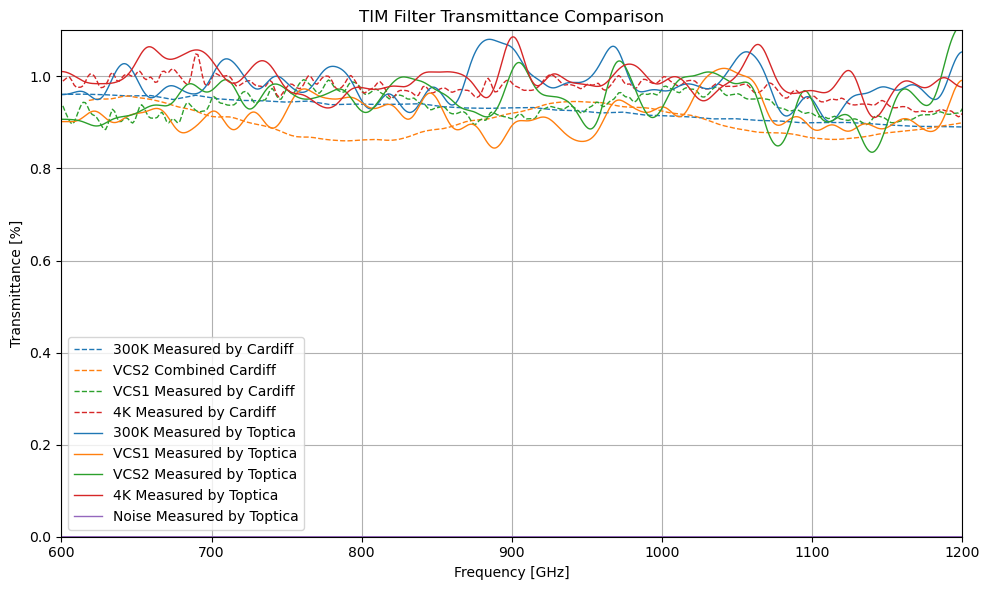

In [12]:
import pickle
import matplotlib.pyplot as plt

with open("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Cardiff_TIM_202505/transmittance_Toptica.pkl", "rb") as f_in:
    results = pickle.load(f_in)

fig, ax = plt.subplots(figsize=(10, 6))


ax.plot(icm2GHz(P34507[0]), P34507[1], label='300K Measured by Cardiff', lw=1, ls='--')

# ax.plot(icm2GHz(P34508[0]), P34508[1], label='VCS2 Measured by Cardiff', lw=1, ls = '--')

# ax.plot(icm2GHz(FP3373ARC[0]), FP3373ARC[1], label='VCS2 Measured by Cardiff', lw=1, ls = '--')

ax.plot(FP3373ARC_freq, combined_T, label='VCS2 Combined Cardiff', lw=1, ls = '--')

ax.plot(icm2GHz(FP3464ARC[0]), FP3464ARC[1], label='VCS1 Measured by Cardiff', lw=1, ls = '--')

ax.plot(icm2GHz(FP3311ARC[0]), FP3311ARC[1], label='4K Measured by Cardiff', lw=1, ls = '--')

# ax.plot(icm2GHz(FP3316[0]), FP3316[1], label='Cardiff 42icm', lw=1, ls = '--')
# ax.plot(icm2GHz(FP3315[0]), FP3315[1], label='Cardiff 33icm', lw=1, ls = '--')

ax.set_xlim([600,1200])
for name, res in results.items():
    freq = res["freq_GHz"]
    T_amp = res["Transmittance_biased"]  # convert to percent
    ax.plot(freq, T_amp, lw=1, ls='-', c=f"C{list(results.keys()).index(name)}",
            label=f"{name} Measured by Toptica")

ax.set_xlabel("Frequency [GHz]")
ax.set_ylabel("Transmittance [%]")
ax.legend()
ax.set_ylim(0, 1.1)
ax.grid(True)
plt.title("TIM Filter Transmittance Comparison")
plt.tight_layout()
plt.show()

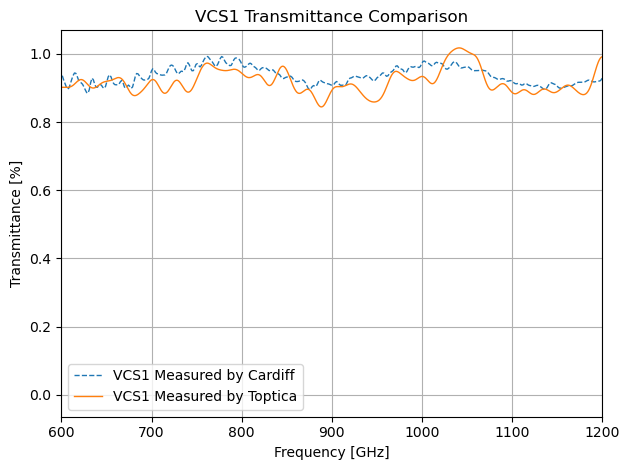

In [13]:
plt.plot(icm2GHz(FP3464ARC[0]), FP3464ARC[1], label='VCS1 Measured by Cardiff', lw=1, ls = '--')
plt.plot(results['VCS1']['freq_GHz'], results['VCS1']['Transmittance_biased'], label='VCS1 Measured by Toptica', lw=1)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.title("VCS1 Transmittance Comparison")
plt.legend()
plt.grid()
plt.xlim(600,1200)

plt.tight_layout()
plt.show()

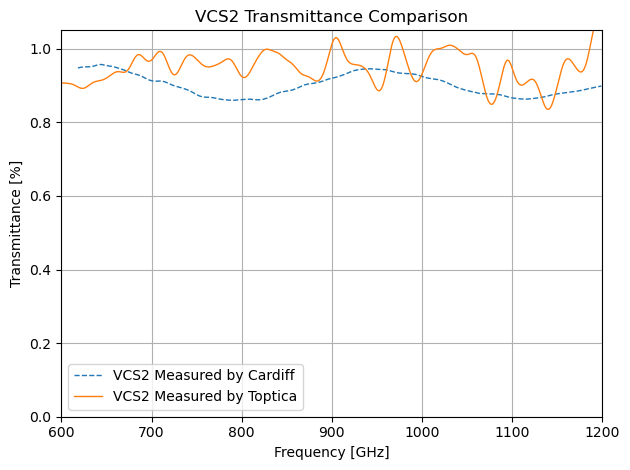

In [14]:
plt.plot(FP3373ARC_freq, combined_T, label='VCS2 Measured by Cardiff', lw=1, ls = '--')
plt.plot(results['VCS2']['freq_GHz'], results['VCS2']['Transmittance_biased'], label='VCS2 Measured by Toptica', lw=1)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.title("VCS2 Transmittance Comparison")
plt.legend()
plt.grid()
plt.xlim(600,1200)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

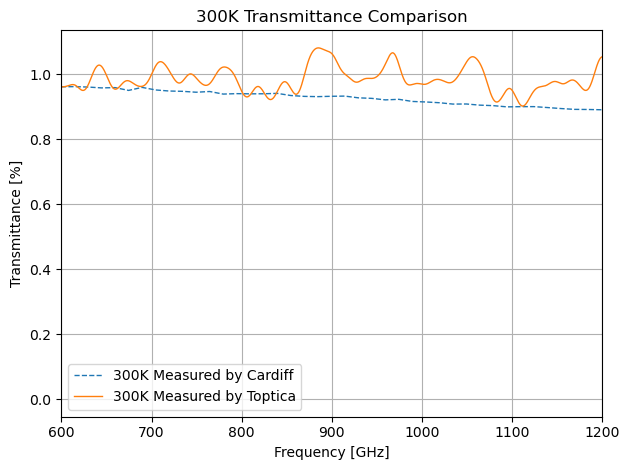

In [15]:
plt.plot(icm2GHz(P34507[0]), P34507[1], label='300K Measured by Cardiff', lw=1, ls = '--')
plt.plot(results['300K']['freq_GHz'], results['300K']['Transmittance_biased'], label='300K Measured by Toptica', lw=1)

plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.legend()
plt.grid()
plt.title("300K Transmittance Comparison")
plt.xlim(600,1200)
plt.tight_layout()
plt.show()

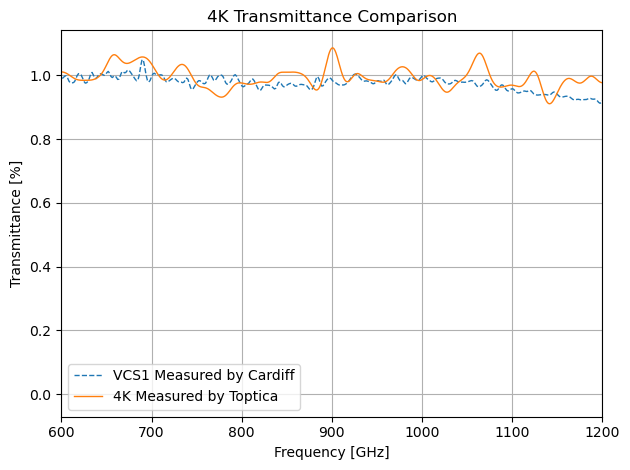

In [16]:
plt.plot(icm2GHz(FP3311ARC[0]), FP3311ARC[1], label='VCS1 Measured by Cardiff', lw=1, ls = '--')
plt.plot(results['4K']['freq_GHz'], results['4K']['Transmittance_biased'], label='4K Measured by Toptica', lw=1)

plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.title("4K Transmittance Comparison")
plt.legend()
plt.grid()
plt.xlim(600,1200)
plt.tight_layout()
plt.show()

In [17]:
with open("/Users/thachdang/Downloads/Transmission_TIM_Filters_03232026/Cardiff_TIM_202505/transmittance_FPU_filters.pkl", "rb") as f_in:
    results_FPU = pickle.load(f_in)


if isinstance(results_FPU, dict):
    keys = list(results_FPU.keys())
    print(f"Keys ({len(keys)}):", keys)
elif hasattr(results_FPU, '__dict__'):
    keys = list(results_FPU.__dict__.keys())
    print(f"Object attributes ({len(keys)}):", keys)
elif hasattr(results_FPU, 'keys'):
    keys = list(results_FPU.keys())
    print(f"Keys ({len(keys)}):", keys)
else:
    print(f"Data type: {type(results_FPU)} — not a key-value structure")
    print("Value:", results_FPU)


Keys (3): ['Filter 3315', 'Filter 3316', 'Noise']


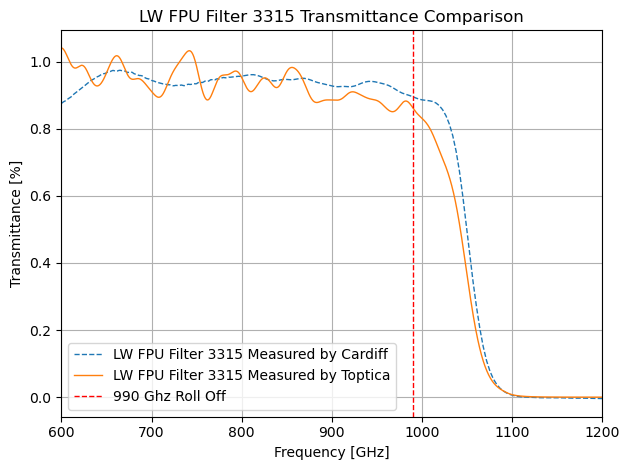

In [18]:
plt.plot(icm2GHz(FP3315[0]), FP3315[1], lw=1, ls = '--', label='LW FPU Filter 3315 Measured by Cardiff')
plt.plot(results_FPU['Filter 3315']['freq_GHz'], results_FPU['Filter 3315']['Transmittance_biased'], label='LW FPU Filter 3315 Measured by Toptica', lw=1)

plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.title("LW FPU Filter 3315 Transmittance Comparison")
plt.axvline(990, ls='--', c='r', lw=1, label='990 Ghz Roll Off')
plt.legend()
plt.grid()
plt.xlim(600,1200)
plt.tight_layout()
plt.show()

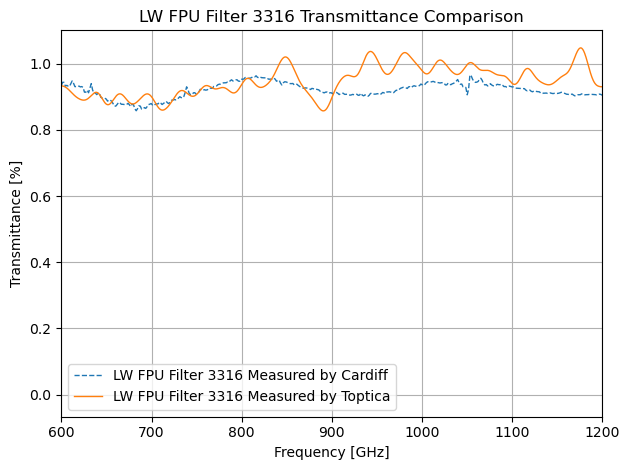

In [19]:
plt.plot(icm2GHz(FP3316[0]), FP3316[1], lw=1, ls = '--', label='LW FPU Filter 3316 Measured by Cardiff')
plt.plot(results_FPU['Filter 3316']['freq_GHz'], results_FPU['Filter 3316']['Transmittance_biased'], label='LW FPU Filter 3316 Measured by Toptica', lw=1)

plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [%]")
plt.title("LW FPU Filter 3316 Transmittance Comparison")
plt.legend()
plt.grid()
plt.xlim(600,1200)
plt.tight_layout()
plt.show()

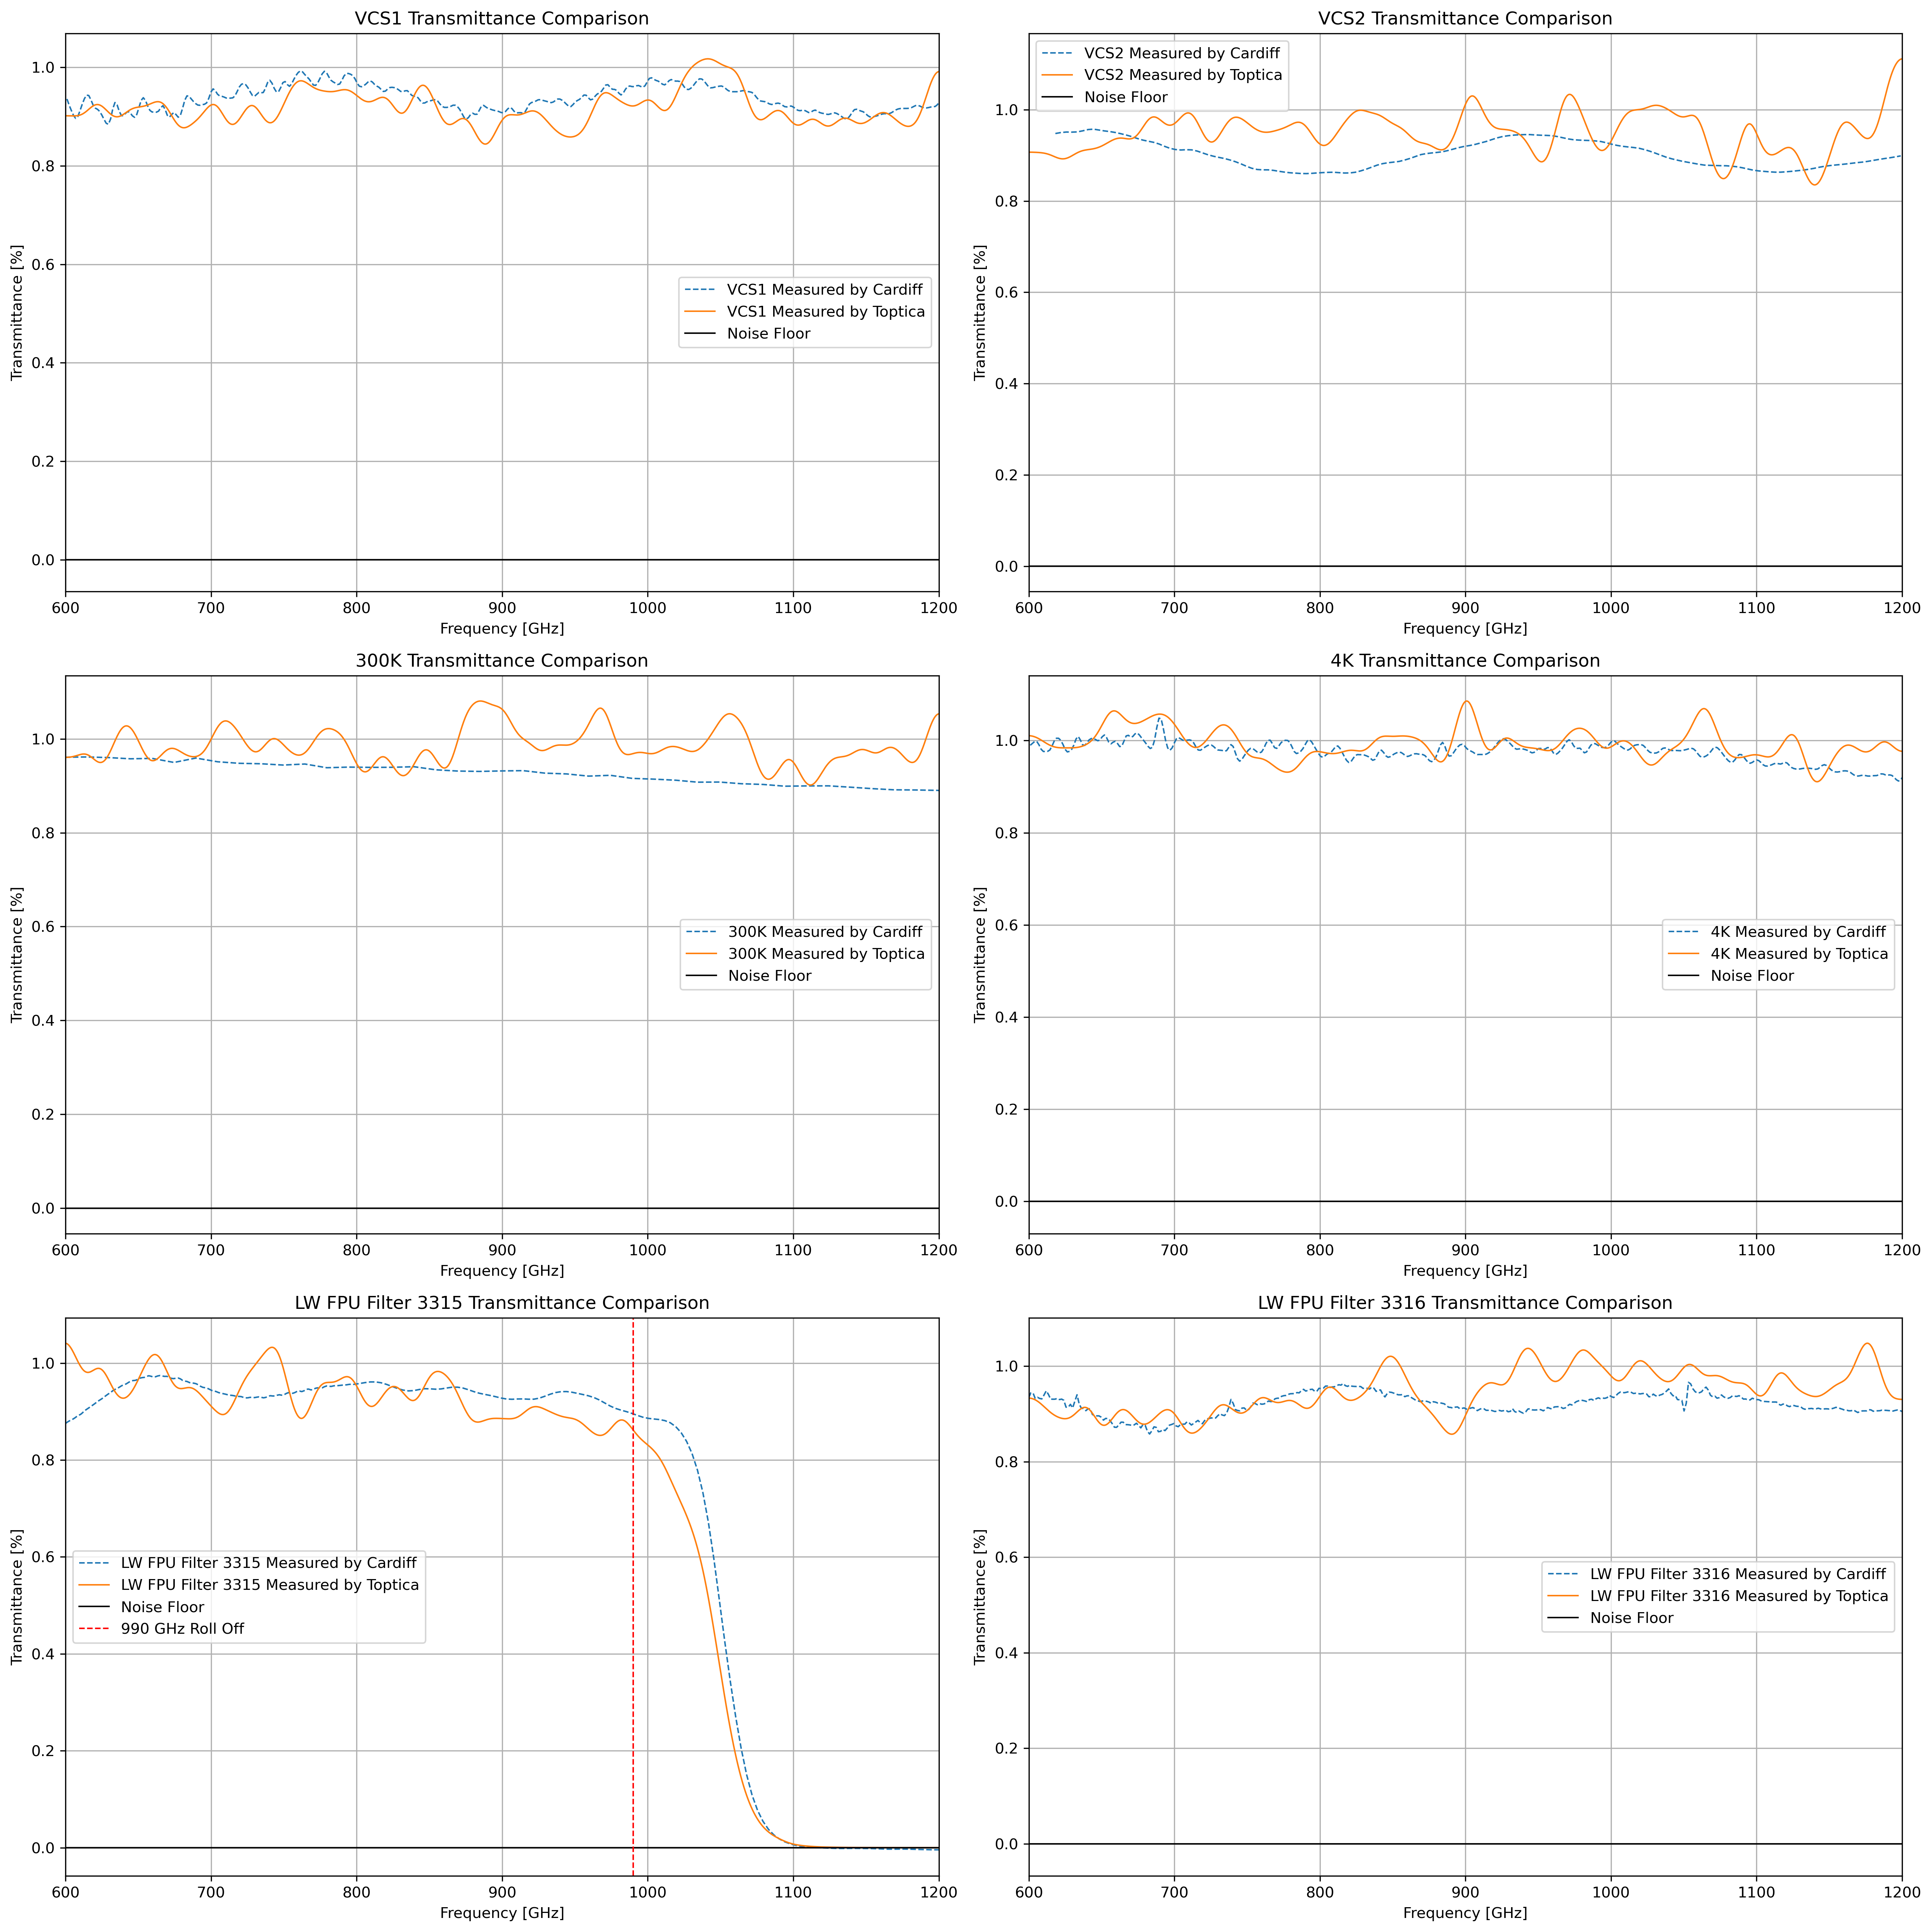

In [20]:
eps_plot = 1e-30
freq_marks = [650, 950, 1200]

freq_GHz_grid = results['VCS1']['freq_GHz']

# ── Drift calculation — Toptica (plots 1–4) ───────────────────────────────────
toptica_samples = {k: v for k, v in results.items() if k != 'Noise'}

avg_drift_stack_toptica = []
for name, d in toptica_samples.items():
    avg_drift_stack_toptica.append(np.mean(
        np.stack([
            np.asarray(d["nu_adj"], dtype=float),
            np.asarray(d["nu_sec"], dtype=float),
            np.asarray(d["nu_med"], dtype=float),
        ], axis=0), axis=0,
    ))
avg_drift_stack_toptica = np.stack(avg_drift_stack_toptica, axis=0)

shared_max_avg_drift_toptica = {}
for nu0 in freq_marks:
    idx_f = int(np.argmin(np.abs(freq_GHz_grid - nu0)))
    shared_max_avg_drift_toptica[nu0] = np.max(avg_drift_stack_toptica[:, idx_f]) * 100

# ── Drift calculation — FPU (plots 5–6) ──────────────────────────────────────
fpu_samples = {k: v for k, v in results_FPU.items() if k != 'Noise'}

avg_drift_stack_fpu = []
for name, d in fpu_samples.items():
    avg_drift_stack_fpu.append(np.mean(
        np.stack([
            np.asarray(d["nu_adj"], dtype=float),
            np.asarray(d["nu_sec"], dtype=float),
            np.asarray(d["nu_med"], dtype=float),
        ], axis=0), axis=0,
    ))
avg_drift_stack_fpu = np.stack(avg_drift_stack_fpu, axis=0)

shared_max_avg_drift_fpu = {}
for nu0 in freq_marks:
    idx_f = int(np.argmin(np.abs(freq_GHz_grid - nu0)))
    shared_max_avg_drift_fpu[nu0] = np.max(avg_drift_stack_fpu[:, idx_f]) * 100

# ── Legend helpers ────────────────────────────────────────────────────────────
def drift_handles_toptica():
    return [
        plt.Line2D([0], [0], color='none',
                   label=rf"$\hat{{\nu}}_{{\max\,\mathrm{{drift}},\,{nu0}\,\mathrm{{GHz}}}}$ = {shared_max_avg_drift_toptica[nu0]:.4f} %")
        for nu0 in freq_marks
    ]

def drift_handles_fpu():
    return [
        plt.Line2D([0], [0], color='none',
                   label=rf"$\hat{{\nu}}_{{\max\,\mathrm{{drift}},\,{nu0}\,\mathrm{{GHz}}}}$ = {shared_max_avg_drift_fpu[nu0]:.4f} %")
        for nu0 in freq_marks
    ]

def add_drift_legend(ax, source='toptica'):
    h, _ = ax.get_legend_handles_labels()
    handles = drift_handles_toptica() if source == 'toptica' else drift_handles_fpu()
    ax.legend(handles=h + handles, loc='best', fontsize=7.5)

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(18, 18), dpi=300)
axes = axes.flatten()

# --- Plot 1: VCS1 ---
axes[0].plot(icm2GHz(FP3464ARC[0]), FP3464ARC[1], label='VCS1 Measured by Cardiff', lw=1, ls='--')
axes[0].plot(results['VCS1']['freq_GHz'], results['VCS1']['Transmittance_biased'], label='VCS1 Measured by Toptica', lw=1)
axes[0].plot(results['Noise']['freq_GHz'], results['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[0].set_xlabel("Frequency [GHz]")
axes[0].set_ylabel("Transmittance [%]")
axes[0].set_title("VCS1 Transmittance Comparison")
axes[0].grid()
axes[0].set_xlim(600, 1200)
axes[0].legend(loc = 'best')
# add_drift_legend(axes[0], 'toptica')

# --- Plot 2: VCS2 ---
axes[1].plot(FP3373ARC_freq, combined_T, label='VCS2 Measured by Cardiff', lw=1, ls='--')
axes[1].plot(results['VCS2']['freq_GHz'], results['VCS2']['Transmittance_biased'], label='VCS2 Measured by Toptica', lw=1)
axes[1].plot(results['Noise']['freq_GHz'], results['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[1].set_xlabel("Frequency [GHz]")
axes[1].set_ylabel("Transmittance [%]")
axes[1].set_title("VCS2 Transmittance Comparison")
axes[1].grid()
axes[1].set_xlim(600, 1200)
axes[1].legend(loc = 'best')

# add_drift_legend(axes[1], 'toptica')

# --- Plot 3: 300K ---
axes[2].plot(icm2GHz(P34507[0]), P34507[1], label='300K Measured by Cardiff', lw=1, ls='--')
axes[2].plot(results['300K']['freq_GHz'], results['300K']['Transmittance_biased'], label='300K Measured by Toptica', lw=1)
axes[2].plot(results['Noise']['freq_GHz'], results['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[2].set_xlabel("Frequency [GHz]")
axes[2].set_ylabel("Transmittance [%]")
axes[2].set_title("300K Transmittance Comparison")
axes[2].grid()
axes[2].set_xlim(600, 1200)
axes[2].legend(loc = 'best')

# add_drift_legend(axes[2], 'toptica')

# --- Plot 4: 4K ---
axes[3].plot(icm2GHz(FP3311ARC[0]), FP3311ARC[1], label='4K Measured by Cardiff', lw=1, ls='--')
axes[3].plot(results['4K']['freq_GHz'], results['4K']['Transmittance_biased'], label='4K Measured by Toptica', lw=1)
axes[3].plot(results['Noise']['freq_GHz'], results['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[3].set_xlabel("Frequency [GHz]")
axes[3].set_ylabel("Transmittance [%]")
axes[3].set_title("4K Transmittance Comparison")
axes[3].grid()
axes[3].set_xlim(600, 1200)
axes[3].legend(loc = 'best')

# add_drift_legend(axes[3], 'toptica')

# --- Plot 5: LW FPU Filter 3315 ---
axes[4].plot(icm2GHz(FP3315[0]), FP3315[1], lw=1, ls='--', label='LW FPU Filter 3315 Measured by Cardiff')
axes[4].plot(results_FPU['Filter 3315']['freq_GHz'], results_FPU['Filter 3315']['Transmittance_biased'], label='LW FPU Filter 3315 Measured by Toptica', lw=1)
axes[4].plot(results_FPU['Noise']['freq_GHz'], results_FPU['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[4].set_xlabel("Frequency [GHz]")
axes[4].set_ylabel("Transmittance [%]")
axes[4].set_title("LW FPU Filter 3315 Transmittance Comparison")
axes[4].axvline(990, ls='--', c='r', lw=1, label='990 GHz Roll Off')
axes[4].grid()
axes[4].set_xlim(600, 1200)
axes[4].legend(loc = 'best')

# add_drift_legend(axes[4], 'fpu')

# --- Plot 6: LW FPU Filter 3316 ---
axes[5].plot(icm2GHz(FP3316[0]), FP3316[1], lw=1, ls='--', label='LW FPU Filter 3316 Measured by Cardiff')
axes[5].plot(results_FPU['Filter 3316']['freq_GHz'], results_FPU['Filter 3316']['Transmittance_biased'], label='LW FPU Filter 3316 Measured by Toptica', lw=1)
axes[5].plot(results_FPU['Noise']['freq_GHz'], results_FPU['Noise']['Transmittance_biased'], label='Noise Floor', lw=1, c='k')
axes[5].set_xlabel("Frequency [GHz]")
axes[5].set_ylabel("Transmittance [%]")
axes[5].set_title("LW FPU Filter 3316 Transmittance Comparison")
axes[5].grid()
axes[5].set_xlim(600, 1200)
axes[5].legend(loc = 'best')

# add_drift_legend(axes[5], 'fpu')

plt.tight_layout()
plt.savefig("LW_filters_ctransmittance_comparison_percent.pdf", dpi=300, bbox_inches='tight')
plt.show()

/var/folders/vx/92gqqjss3zsd40kfns0vpzg40000gn/T/ipykernel_48379/2543498217.py:5: RuntimeWarning: invalid value encountered in log10
  return 10 * np.log10(x)


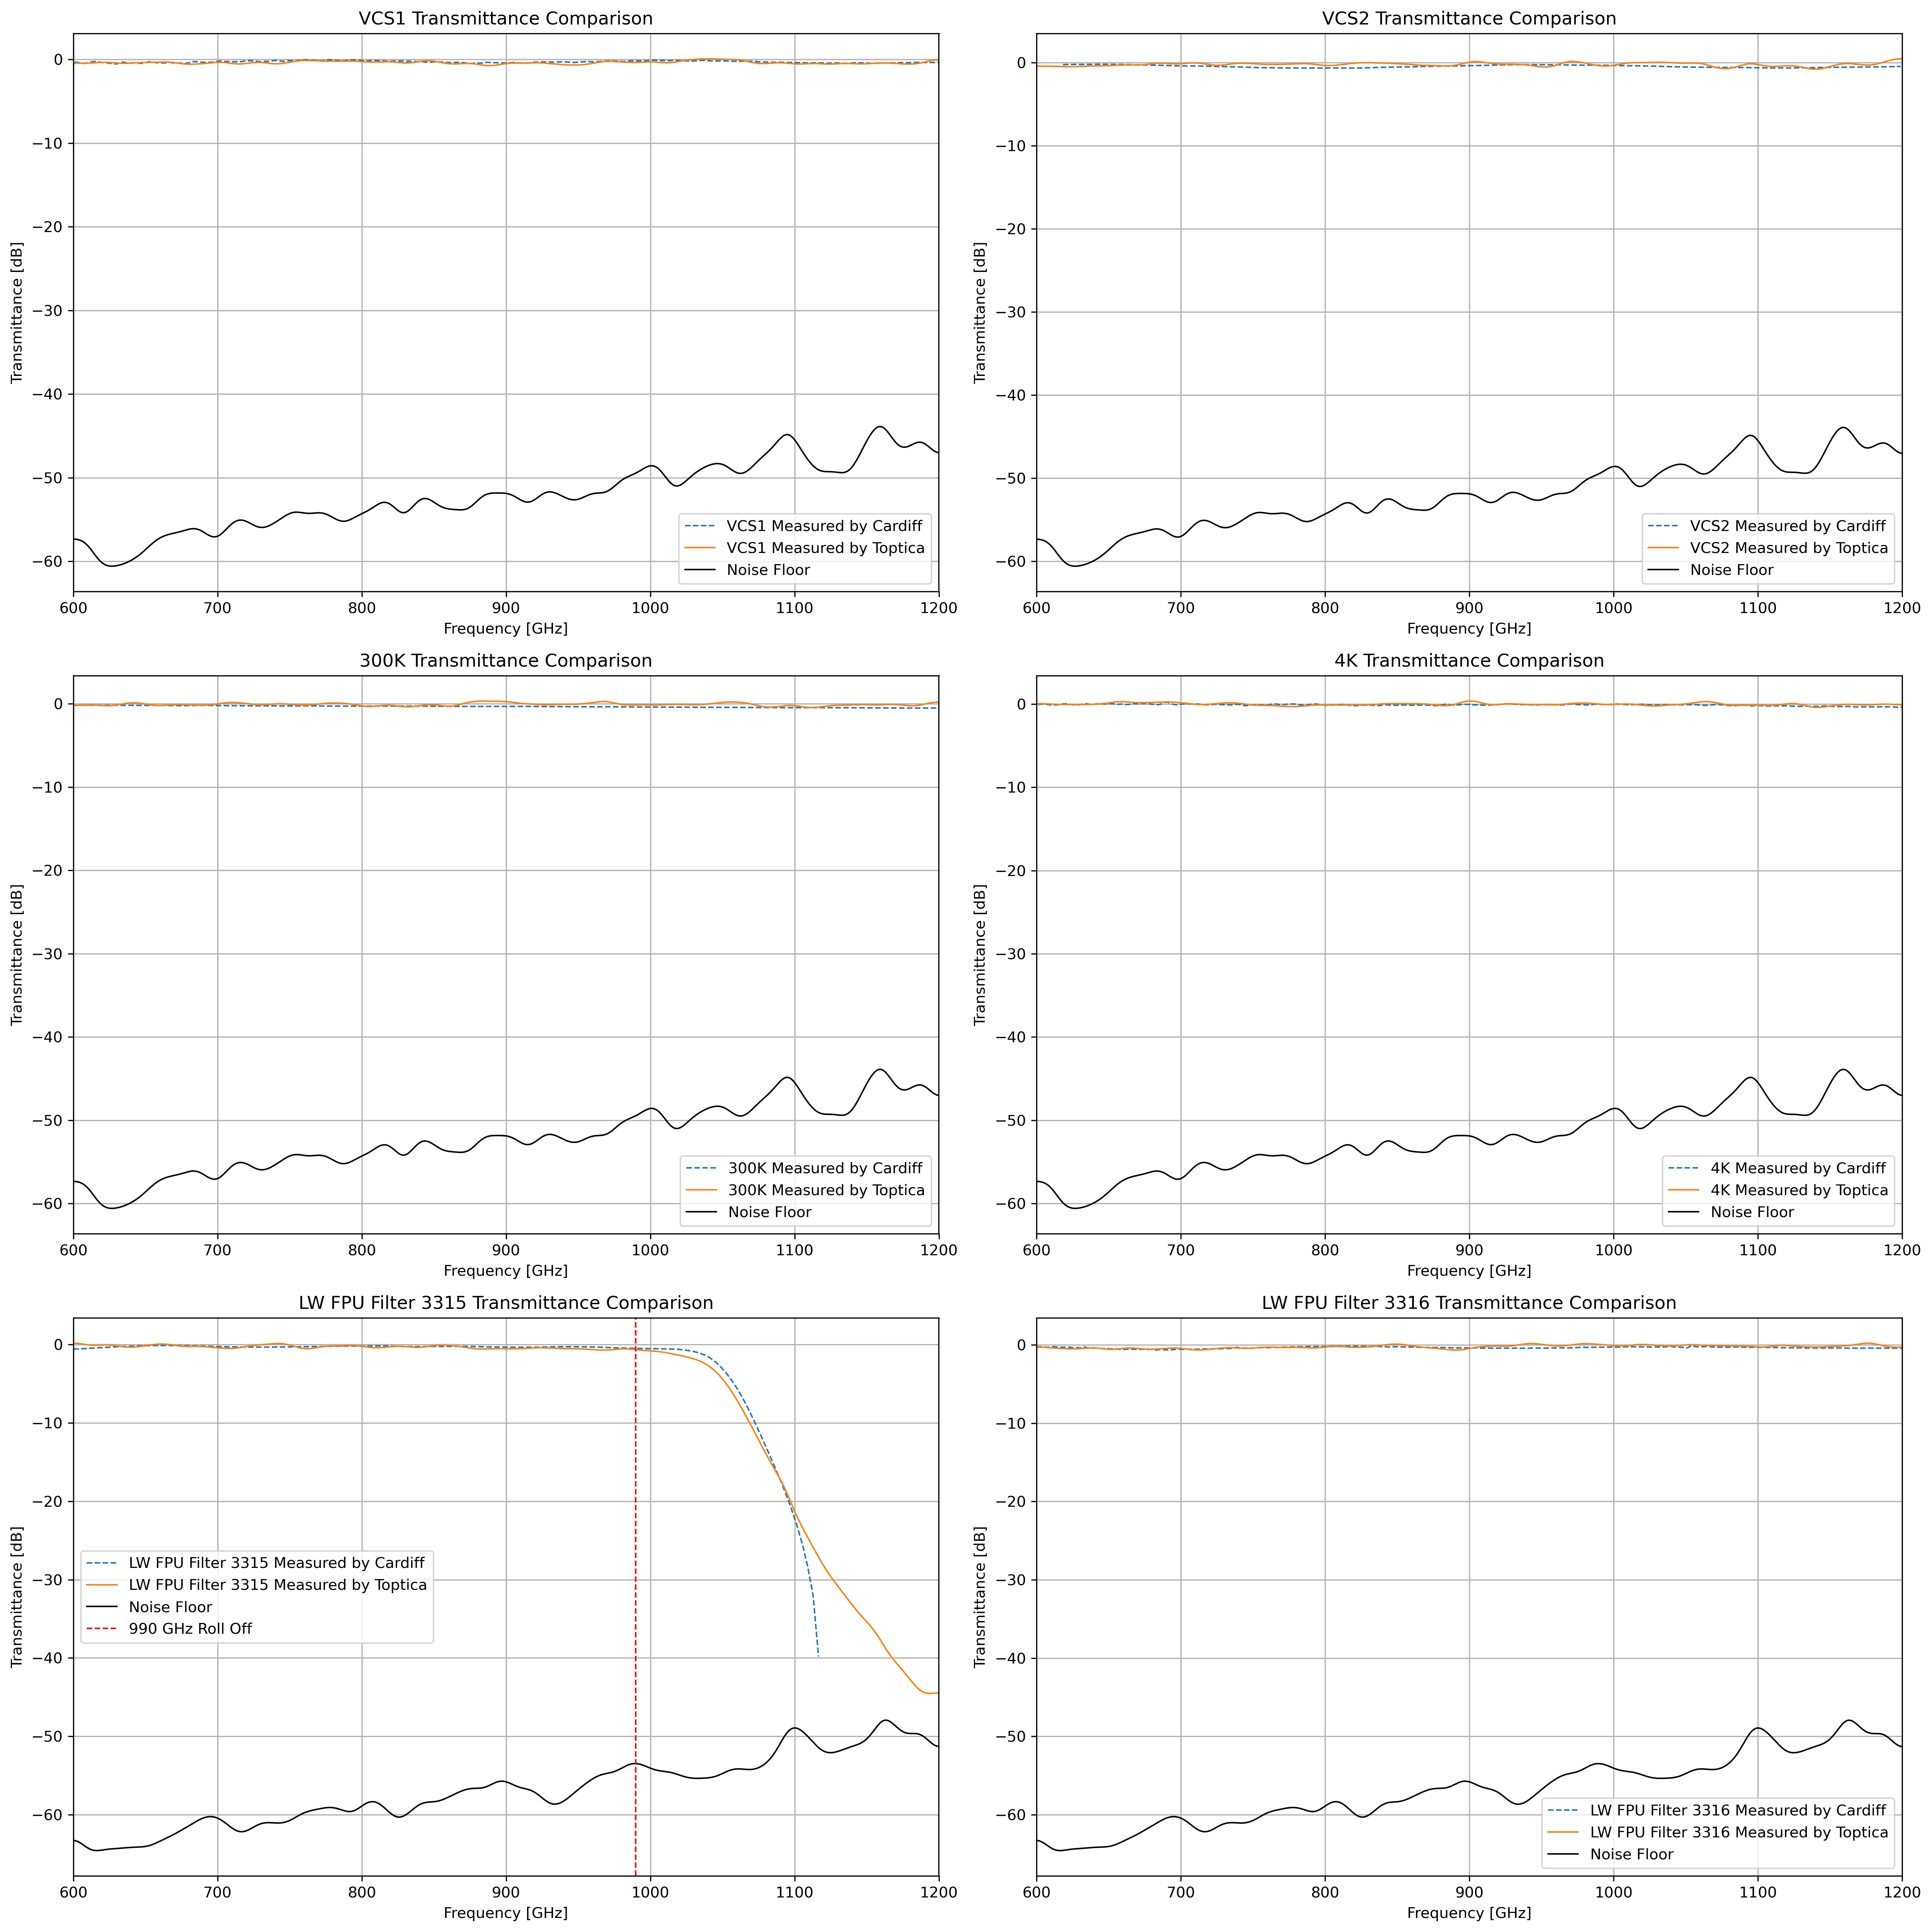

In [21]:
eps_plot = 1e-30
freq_marks = [650, 950, 1200]

def to_dB(x):
    return 10 * np.log10(x)

freq_GHz_grid = results['VCS1']['freq_GHz']

# ── Drift calculation — Toptica (plots 1–4) ───────────────────────────────────
toptica_samples = {k: v for k, v in results.items() if k != 'Noise'}

avg_drift_stack_toptica = []
for name, d in toptica_samples.items():
    avg_drift_stack_toptica.append(np.mean(
        np.stack([
            np.asarray(d["nu_adj"], dtype=float),
            np.asarray(d["nu_sec"], dtype=float),
            np.asarray(d["nu_med"], dtype=float),
        ], axis=0), axis=0,
    ))
avg_drift_stack_toptica = np.stack(avg_drift_stack_toptica, axis=0)

shared_max_avg_drift_toptica = {}
for nu0 in freq_marks:
    idx_f = int(np.argmin(np.abs(freq_GHz_grid - nu0)))
    shared_max_avg_drift_toptica[nu0] = 10 * np.log10(np.clip(np.max(avg_drift_stack_toptica[:, idx_f]), eps_plot, None))

# ── Drift calculation — FPU (plots 5–6) ──────────────────────────────────────
fpu_samples = {k: v for k, v in results_FPU.items() if k != 'Noise'}

avg_drift_stack_fpu = []
for name, d in fpu_samples.items():
    avg_drift_stack_fpu.append(np.mean(
        np.stack([
            np.asarray(d["nu_adj"], dtype=float),
            np.asarray(d["nu_sec"], dtype=float),
            np.asarray(d["nu_med"], dtype=float),
        ], axis=0), axis=0,
    ))
avg_drift_stack_fpu = np.stack(avg_drift_stack_fpu, axis=0)

shared_max_avg_drift_fpu = {}
for nu0 in freq_marks:
    idx_f = int(np.argmin(np.abs(freq_GHz_grid - nu0)))
    shared_max_avg_drift_fpu[nu0] = 10 * np.log10(np.clip(np.max(avg_drift_stack_fpu[:, idx_f]), eps_plot, None))

# ── Legend helpers ────────────────────────────────────────────────────────────
def drift_handles_toptica():
    return [
        plt.Line2D([0], [0], color='none',
                   label=rf"$\hat{{\nu}}_{{\max\,\mathrm{{drift}},\,{nu0}\,\mathrm{{GHz}}}}$ = {np.abs(shared_max_avg_drift_toptica[nu0]):.2f} dB")
        for nu0 in freq_marks
    ]

def drift_handles_fpu():
    return [
        plt.Line2D([0], [0], color='none',
                   label=rf"$\hat{{\nu}}_{{\max\,\mathrm{{drift}},\,{nu0}\,\mathrm{{GHz}}}}$ = {np.abs(shared_max_avg_drift_fpu[nu0]):.2f} dB")
        for nu0 in freq_marks
    ]

def add_drift_legend(ax, source='toptica'):
    h, _ = ax.get_legend_handles_labels()
    handles = drift_handles_toptica() if source == 'toptica' else drift_handles_fpu()
    ax.legend(handles=h + handles, loc='best', fontsize=7.5)

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(18, 18), dpi=300)
axes = axes.flatten()

# --- Plot 1: VCS1 ---
axes[0].plot(icm2GHz(FP3464ARC[0]), to_dB(FP3464ARC[1]), label='VCS1 Measured by Cardiff', lw=1, ls='--')
axes[0].plot(results['VCS1']['freq_GHz'], to_dB(results['VCS1']['Transmittance_biased']), label='VCS1 Measured by Toptica', lw=1)
axes[0].plot(results['Noise']['freq_GHz'], to_dB(results['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[0].set_xlabel("Frequency [GHz]")
axes[0].set_ylabel("Transmittance [dB]")
axes[0].set_title("VCS1 Transmittance Comparison")
axes[0].grid()
axes[0].set_xlim(600, 1200)
axes[0].legend(loc = 'best')

# add_drift_legend(axes[0], 'toptica')

# --- Plot 2: VCS2 ---
axes[1].plot(FP3373ARC_freq, to_dB(combined_T), label='VCS2 Measured by Cardiff', lw=1, ls='--')
axes[1].plot(results['VCS2']['freq_GHz'], to_dB(results['VCS2']['Transmittance_biased']), label='VCS2 Measured by Toptica', lw=1)
axes[1].plot(results['Noise']['freq_GHz'], to_dB(results['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[1].set_xlabel("Frequency [GHz]")
axes[1].set_ylabel("Transmittance [dB]")
axes[1].set_title("VCS2 Transmittance Comparison")
axes[1].grid()
axes[1].set_xlim(600, 1200)
axes[1].legend(loc = 'best')

# add_drift_legend(axes[1], 'toptica')

# --- Plot 3: 300K ---
axes[2].plot(icm2GHz(P34507[0]), to_dB(P34507[1]), label='300K Measured by Cardiff', lw=1, ls='--')
axes[2].plot(results['300K']['freq_GHz'], to_dB(results['300K']['Transmittance_biased']), label='300K Measured by Toptica', lw=1)
axes[2].plot(results['Noise']['freq_GHz'], to_dB(results['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[2].set_xlabel("Frequency [GHz]")
axes[2].set_ylabel("Transmittance [dB]")
axes[2].set_title("300K Transmittance Comparison")
axes[2].grid()
axes[2].set_xlim(600, 1200)
axes[2].legend(loc = 'best')

# add_drift_legend(axes[2], 'toptica')

# --- Plot 4: 4K ---
axes[3].plot(icm2GHz(FP3311ARC[0]), to_dB(FP3311ARC[1]), label='4K Measured by Cardiff', lw=1, ls='--')
axes[3].plot(results['4K']['freq_GHz'], to_dB(results['4K']['Transmittance_biased']), label='4K Measured by Toptica', lw=1)
axes[3].plot(results['Noise']['freq_GHz'], to_dB(results['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[3].set_xlabel("Frequency [GHz]")
axes[3].set_ylabel("Transmittance [dB]")
axes[3].set_title("4K Transmittance Comparison")
axes[3].grid()
axes[3].set_xlim(600, 1200)
axes[3].legend(loc = 'best')

# add_drift_legend(axes[3], 'toptica')

# --- Plot 5: LW FPU Filter 3315 ---
axes[4].plot(icm2GHz(FP3315[0]), to_dB(FP3315[1]), lw=1, ls='--', label='LW FPU Filter 3315 Measured by Cardiff')
axes[4].plot(results_FPU['Filter 3315']['freq_GHz'], to_dB(results_FPU['Filter 3315']['Transmittance_biased']), label='LW FPU Filter 3315 Measured by Toptica', lw=1)
axes[4].plot(results_FPU['Noise']['freq_GHz'], to_dB(results_FPU['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[4].set_xlabel("Frequency [GHz]")
axes[4].set_ylabel("Transmittance [dB]")
axes[4].set_title("LW FPU Filter 3315 Transmittance Comparison")
axes[4].axvline(990, ls='--', c='r', lw=1, label='990 GHz Roll Off')
axes[4].grid()
axes[4].set_xlim(600, 1200)
axes[4].legend(loc = 'best')

# add_drift_legend(axes[4], 'fpu')

# --- Plot 6: LW FPU Filter 3316 ---
axes[5].plot(icm2GHz(FP3316[0]), to_dB(FP3316[1]), lw=1, ls='--', label='LW FPU Filter 3316 Measured by Cardiff')
axes[5].plot(results_FPU['Filter 3316']['freq_GHz'], to_dB(results_FPU['Filter 3316']['Transmittance_biased']), label='LW FPU Filter 3316 Measured by Toptica', lw=1)
axes[5].plot(results_FPU['Noise']['freq_GHz'], to_dB(results_FPU['Noise']['Transmittance_biased']), label='Noise Floor', lw=1, c='k')
axes[5].set_xlabel("Frequency [GHz]")
axes[5].set_ylabel("Transmittance [dB]")
axes[5].set_title("LW FPU Filter 3316 Transmittance Comparison")
axes[5].grid()
axes[5].set_xlim(600, 1200)
axes[5].legend(loc = 'best')

# add_drift_legend(axes[5], 'fpu')

plt.tight_layout()
plt.savefig("LW_filters_transmittance_comparison_dB.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [22]:
def interp_to_grid(x_src, y_src, x_grid):
    idx = np.argsort(x_src)
    return np.interp(
        x_grid,
        np.asarray(x_src)[idx],
        np.asarray(y_src)[idx],
        left=np.nan,
        right=np.nan
    )

# Choose one common x-axis.
# Usually use the dense Cardiff/filter grid, for example FP3464ARC[0]
x_common = FP3464ARC[0]

combined_T_interp = interp_to_grid(FP3373ARC_freq, combined_T, x_common)
P34507_interp    = interp_to_grid(P34507[0],    P34507[1],    x_common)
FP3311_interp    = interp_to_grid(FP3311ARC[0], FP3311ARC[1], x_common)
FP3315_interp    = interp_to_grid(FP3315[0],    FP3315[1],    x_common)
FP3316_interp    = interp_to_grid(FP3316[0],    FP3316[1],    x_common)

Total_transmittance_dB_cardiff = (
    to_dB(FP3464ARC[1])
    + to_dB(combined_T_interp)
    + to_dB(P34507_interp)
    + to_dB(FP3311_interp)
    + to_dB(FP3315_interp)
    + to_dB(FP3316_interp)
)

/var/folders/vx/92gqqjss3zsd40kfns0vpzg40000gn/T/ipykernel_48379/2543498217.py:5: RuntimeWarning: invalid value encountered in log10
  return 10 * np.log10(x)


In [23]:
len(combined_T_interp), len(P34507_interp), len(FP3311_interp), len(FP3315_interp), len(FP3316_interp), len(x_common)

(2582, 2582, 2582, 2582, 2582, 2582)

In [24]:
len(Total_transmittance_dB_cardiff), len(x_common)

(2582, 2582)

In [25]:
print(x_common)

[ 20.046792  20.096784  20.146776 ... 299.625    299.75     299.875   ]


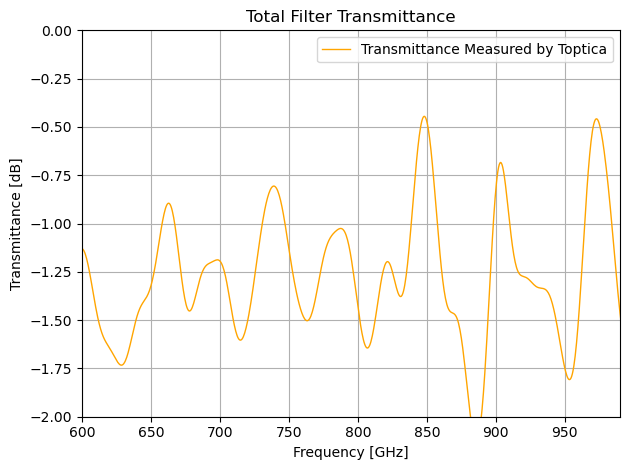

In [30]:
Total_transmittance_dB_toptica = to_dB(results['VCS1']['Transmittance_biased'])+to_dB(results['VCS2']['Transmittance_biased'])+to_dB(results['300K']['Transmittance_biased'])+to_dB(results['4K']['Transmittance_biased'])\
                        +to_dB(results_FPU['Filter 3315']['Transmittance_biased'])+to_dB(results_FPU['Filter 3316']['Transmittance_biased'])
plt.plot(results['VCS1']['freq_GHz'], Total_transmittance_dB_toptica, label='Transmittance Measured by Toptica', lw=1, color = 'orange')
# plt.plot(x_common, Total_transmittance_dB_cardiff, label='Transmittance Measured by Cardiff', lw=1, color = 'blue', ls = '--')
plt.xlim(600,990)
plt.ylim(-2, 0)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Transmittance [dB]")
plt.title("Total Filter Transmittance")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

#FPU 
42 icm = LW FPU
33 icm = LW FPU
57 icm = SW FPU
42 icm = SW FPU

#Cryo 
Multiply Cardiff VCS2 Special Thermal and Cardiff C7.5 Shader = VCS2 for VCS2 Filter as measured Toptica

In [27]:
# fig,ax=plt.subplots(figsize=(8,5), dpi=160)

# plt.plot(window[0],window[1], label='window')
# plt.plot(IR300[0],IR300[1], label='300K IR')
# plt.plot(IRVCS[0],IRVCS[1], label='VCS IR')
# plt.plot(LPEVCS[0],LPEVCS[1], label='VCS LPE')
# plt.plot(IR4K[0],IR4K[1], label='4K IR')
# plt.plot(LPE4K[0],LPE4K[1], label='4K LPE')
# plt.plot(OBLPE4K[0],OBLPE4K[1], label='4K OB LPE')

# # plt.plot(icm2um(LPE4K_E[0]), LPE4K_E[1], label='Cardiff 100icm')
# # plt.plot(icm2um(LPE4K_G[0]), LPE4K_G[1], label='Cardiff 57icm')
# # plt.plot(icm2um(F42icm[0]), F42icm[1], label='Cardiff 42icm')

# plt.axvspan(240,420, color='g', alpha=0.2, label='TIM Band', lw=0)

# # plt.xlim([200,500])
# # plt.ylim([0.7,1.0])
# plt.xscale('log')
# ax.set_xticks([200, 300,400, 500])
# ax.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())

# plt.xlabel('wavelength [um]')
# plt.ylabel('transmissivity ')

# plt.legend(frameon=0,fontsize=8)